In [2]:
import pandas as pd
from pathlib import Path
def extract_pid(filename):
    part = filename.split('_')[0]          
    pid_full = part.split('-')[1]          
    pid = pid_full[5:]                     
    return pid
    
data_path=Path("/Users/arkaroy457/Desktop/NESI_review_materials/Data")

df_BWH=pd.read_csv(data_path/"GCS_BWH_HarvardEEG_metadata.csv")
df_MGH=pd.read_csv(data_path/"GCS_MGH_HarvardEEG_metadata.csv")

print("BWH shape:",df_BWH.shape)
print("MGH shape:",df_MGH.shape)

print("\nSame columns:",df_BWH.columns.tolist()==df_MGH.columns.tolist())

df_GCS=pd.concat([df_BWH,df_MGH],ignore_index=True)
#df_GCS=df_GCS[pd.to_numeric(df_GCS['R PHS IP GCS'],errors='coerce')<=0].copy()

#print(df_GCS['R PHS IP GCS'].value_counts().sort_index())
print("\nCombined shape:",df_GCS.shape)

BWH shape: (74815, 20)
MGH shape: (54801, 20)

Same columns: True

Combined shape: (129616, 20)


# **Filetring the Cohort**
- **Chosse only patients who has multiple GCS for same EEG session**

In [5]:
df_GCS2=df_GCS[['BDSPPatientID','GCSRecordedDTS','R CPN GLASGOW COMA SCALE SCORE','BidsFolder','SessionID']].copy()

# Count distinct GCS values within each patient + BIDS folder + session
rass_counts=df_GCS2.groupby(
    ['BDSPPatientID','BidsFolder','SessionID']
)['R CPN GLASGOW COMA SCALE SCORE'].nunique().reset_index(name='N_distinct_GCS')

# Keep groups having >1 distinct GCS value
multiple_rass_groups=rass_counts[rass_counts['N_distinct_GCS']>1]

# Get all original rows belonging to those groups
df_multiple_GCS=df_GCS2.merge(
    multiple_rass_groups,
    on=['BDSPPatientID','BidsFolder','SessionID'],
    how='inner'
).sort_values(
    ['BDSPPatientID','BidsFolder','SessionID','GCSRecordedDTS']
)

df_multiple_GCS=df_multiple_GCS.sort_values(
    by=['BDSPPatientID','SessionID']
).reset_index(drop=True)


df_multiple_GCS["GCSRecordedDTS"]=pd.to_datetime(df_multiple_GCS["GCSRecordedDTS"],errors="coerce")

df_multiple_GCS=df_multiple_GCS.sort_values(
    ["BDSPPatientID","BidsFolder","SessionID","GCSRecordedDTS"]
).reset_index(drop=True)

df_multiple_GCS["SegmentNumber"]=(
    df_multiple_GCS.groupby(["BDSPPatientID","BidsFolder","SessionID"]).cumcount()+1
)

df_multiple_GCS["PossibleFilename"]=(
    df_multiple_GCS["BidsFolder"].astype(str)
    +"_ses-"
    +df_multiple_GCS["SessionID"].astype(int).astype(str)
    +"_eeg_10min_seg"
    +df_multiple_GCS["SegmentNumber"].astype(str)
)

df_multiple_GCS.drop(columns="SegmentNumber",inplace=True)


print(f"Number of patient-session groups with multiple distinct GCS values: {len(multiple_rass_groups)}")
print(f"Number of unique patients: {multiple_rass_groups['BDSPPatientID'].nunique()}")
len(df_multiple_GCS)

Number of patient-session groups with multiple distinct GCS values: 10563
Number of unique patients: 4457


85234

# **Get the EEG filenames and NESI from the NESI Result Metdata**

In [7]:
nesi_path="/Users/arkaroy457/Desktop/NESI_review_materials/Data/NESIscores_full_dataset_result.csv"
df_NESI=pd.read_csv(nesi_path)

df_NESI_GCS=df_NESI[df_NESI["Dataset"]=="GCS"].copy()

df_NESI_GCS["Filename"]=(
    df_NESI_GCS["MorgothOutputFilename"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.csv$","",regex=True)
)

df_NESI_GCS["BidsFolder"]=df_NESI_GCS["Filename"].str.extract(r"^(sub-[^_]+)")
df_NESI_GCS["SessionID"]=pd.to_numeric(
    df_NESI_GCS["Filename"].str.extract(r"_ses-(\d+)")[0],
    errors="coerce"
).astype("Int64")

df_NESI_GCS = df_NESI_GCS[['BDSPPatientID',	'Dataset', 'Filename', 'BidsFolder', 'SessionID',
                            'RawScore',	'Split', 'NESI']]

df_NESI_GCS=df_NESI_GCS.sort_values(
    by=['BDSPPatientID','SessionID']
).reset_index(drop=True)

print("Total GCS rows:",len(df_NESI_GCS))
print("Unique filenames:",df_NESI_GCS["Filename"].nunique())
print("Unique patients:",df_NESI_GCS["BDSPPatientID"].nunique())

Total GCS rows: 110836
Unique filenames: 110836
Unique patients: 7112


# **Attach the NESI**

In [9]:
import pandas as pd

# Make matching columns compatible
df_NESI_GCS["BDSPPatientID"]=df_NESI_GCS["BDSPPatientID"].astype(str).str.strip()
df_multiple_GCS["BDSPPatientID"]=df_multiple_GCS["BDSPPatientID"].astype(str).str.strip()

df_NESI_GCS["SessionID"]=pd.to_numeric(df_NESI_GCS["SessionID"],errors="coerce")
df_multiple_GCS["SessionID"]=pd.to_numeric(df_multiple_GCS["SessionID"],errors="coerce")

df_NESI_GCS["RawScore"]=pd.to_numeric(df_NESI_GCS["RawScore"],errors="coerce")
df_multiple_GCS["R CPN GLASGOW COMA SCALE SCORE"]=pd.to_numeric(df_multiple_GCS["R CPN GLASGOW COMA SCALE SCORE"],errors="coerce")

df_NESI_GCS["Filename"]=df_NESI_GCS["Filename"].astype(str).str.strip()
df_multiple_GCS["PossibleFilename"]=df_multiple_GCS["PossibleFilename"].astype(str).str.strip()

# Keep only columns required from df_multiple_GCS
df_rass_match=df_multiple_GCS[
    [
        "BDSPPatientID",
        "SessionID",
        "PossibleFilename",
        "R CPN GLASGOW COMA SCALE SCORE",
        "GCSRecordedDTS",
        "N_distinct_GCS"
    ]
].copy()

# Strict match:
# BDSPPatientID == BDSPPatientID
# SessionID      == SessionID
# Filename       == PossibleFilename
# RawScore       == R CPN GLASGOW COMA SCALE SCORE
df_NESI_GCS=df_NESI_GCS.merge(
    df_rass_match,
    left_on=[
        "BDSPPatientID",
        "SessionID",
        "Filename",
        "RawScore"
    ],
    right_on=[
        "BDSPPatientID",
        "SessionID",
        "PossibleFilename",
        "R CPN GLASGOW COMA SCALE SCORE"
    ],
    how="left",
    validate="many_to_one"
)

# Remove temporary matching columns
df_NESI_GCS.drop(
    columns=["PossibleFilename","R CPN GLASGOW COMA SCALE SCORE"],
    inplace=True
)

# Check matching result
n_total=len(df_NESI_GCS)
n_matched=df_NESI_GCS["GCSRecordedDTS"].notna().sum()
n_unmatched=df_NESI_GCS["GCSRecordedDTS"].isna().sum()

print(f"Total df_NESI_GCS rows : {n_total}")
print(f"Successfully matched    : {n_matched}")
print(f"Unmatched               : {n_unmatched}")
print(f"Match percentage        : {100*n_matched/n_total:.2f}%")

Total df_NESI_GCS rows : 110836
Successfully matched    : 67378
Unmatched               : 43458
Match percentage        : 60.79%


In [10]:
# Remove rows where BOTH GCSRecordedDTS and N_distinct_GCS are NaN
df_NESI_GCS_final=df_NESI_GCS.dropna(
    subset=["GCSRecordedDTS","N_distinct_GCS"],
    how="all"
).reset_index(drop=True)

# Summary
print(f"Total rows                    : {len(df_NESI_GCS_final)}")
print(f"Unique subjects               : {df_NESI_GCS_final['BDSPPatientID'].nunique()}")
print(f"Unique BIDS folders           : {df_NESI_GCS_final['BidsFolder'].nunique()}")
print(f"Unique subject-session pairs  : {df_NESI_GCS_final[['BDSPPatientID','BidsFolder','SessionID']].drop_duplicates().shape[0]}")
print(f"Unique filenames/EEG segments : {df_NESI_GCS_final['Filename'].nunique()}")
print(f"Unique GCS assessment times  : {df_NESI_GCS_final[['BDSPPatientID','BidsFolder','SessionID','GCSRecordedDTS']].drop_duplicates().shape[0]}")

print("\nGCS score distribution:")
print(df_NESI_GCS_final["RawScore"].value_counts().sort_index())

print("\nRows by split:")
print(df_NESI_GCS_final["Split"].value_counts(dropna=False))

Total rows                    : 67378
Unique subjects               : 4350
Unique BIDS folders           : 4381
Unique subject-session pairs  : 9895
Unique filenames/EEG segments : 67378
Unique GCS assessment times  : 67378

GCS score distribution:
RawScore
3     3716
4     1839
5     3200
6     5678
7     7117
8     6529
9     6221
10    7370
11    4446
12    2068
13    4838
14    8157
15    6199
Name: count, dtype: int64

Rows by split:
Split
Train    59570
Test      4158
Val       3650
Name: count, dtype: int64


NESI-GCS ANALYSIS | SPLIT: ALL
Input rows             : 67378
Unique patients        : 4350
All <=60-min pairs      : 21778
Stable pairs           : 17341
Worsening pairs        : 2028
Improvement pairs      : 2409
Overall stable NESI SD : 0.375 (95% CI 0.365–0.386)

A. STABLE GCS — NESI SD
            count   mean  median    std
Stable_GCS                             
3            1301  0.305   0.189  0.346
4             575  0.317   0.221  0.307
5            1101  0.335   0.227  0.337
6            1755  0.356   0.240  0.356
7            2235  0.337   0.231  0.334
8            1677  0.344   0.244  0.337
9            1574  0.386   0.289  0.357
10           1657  0.408   0.298  0.386
11            994  0.404   0.300  0.366
12            535  0.379   0.281  0.348
13            971  0.433   0.312  0.395
14           1729  0.430   0.318  0.385
15           1237  0.445   0.299  0.437

B. GCS WORSENING — DELTA NESI
           count   mean  median    std
Delta_GCS                             

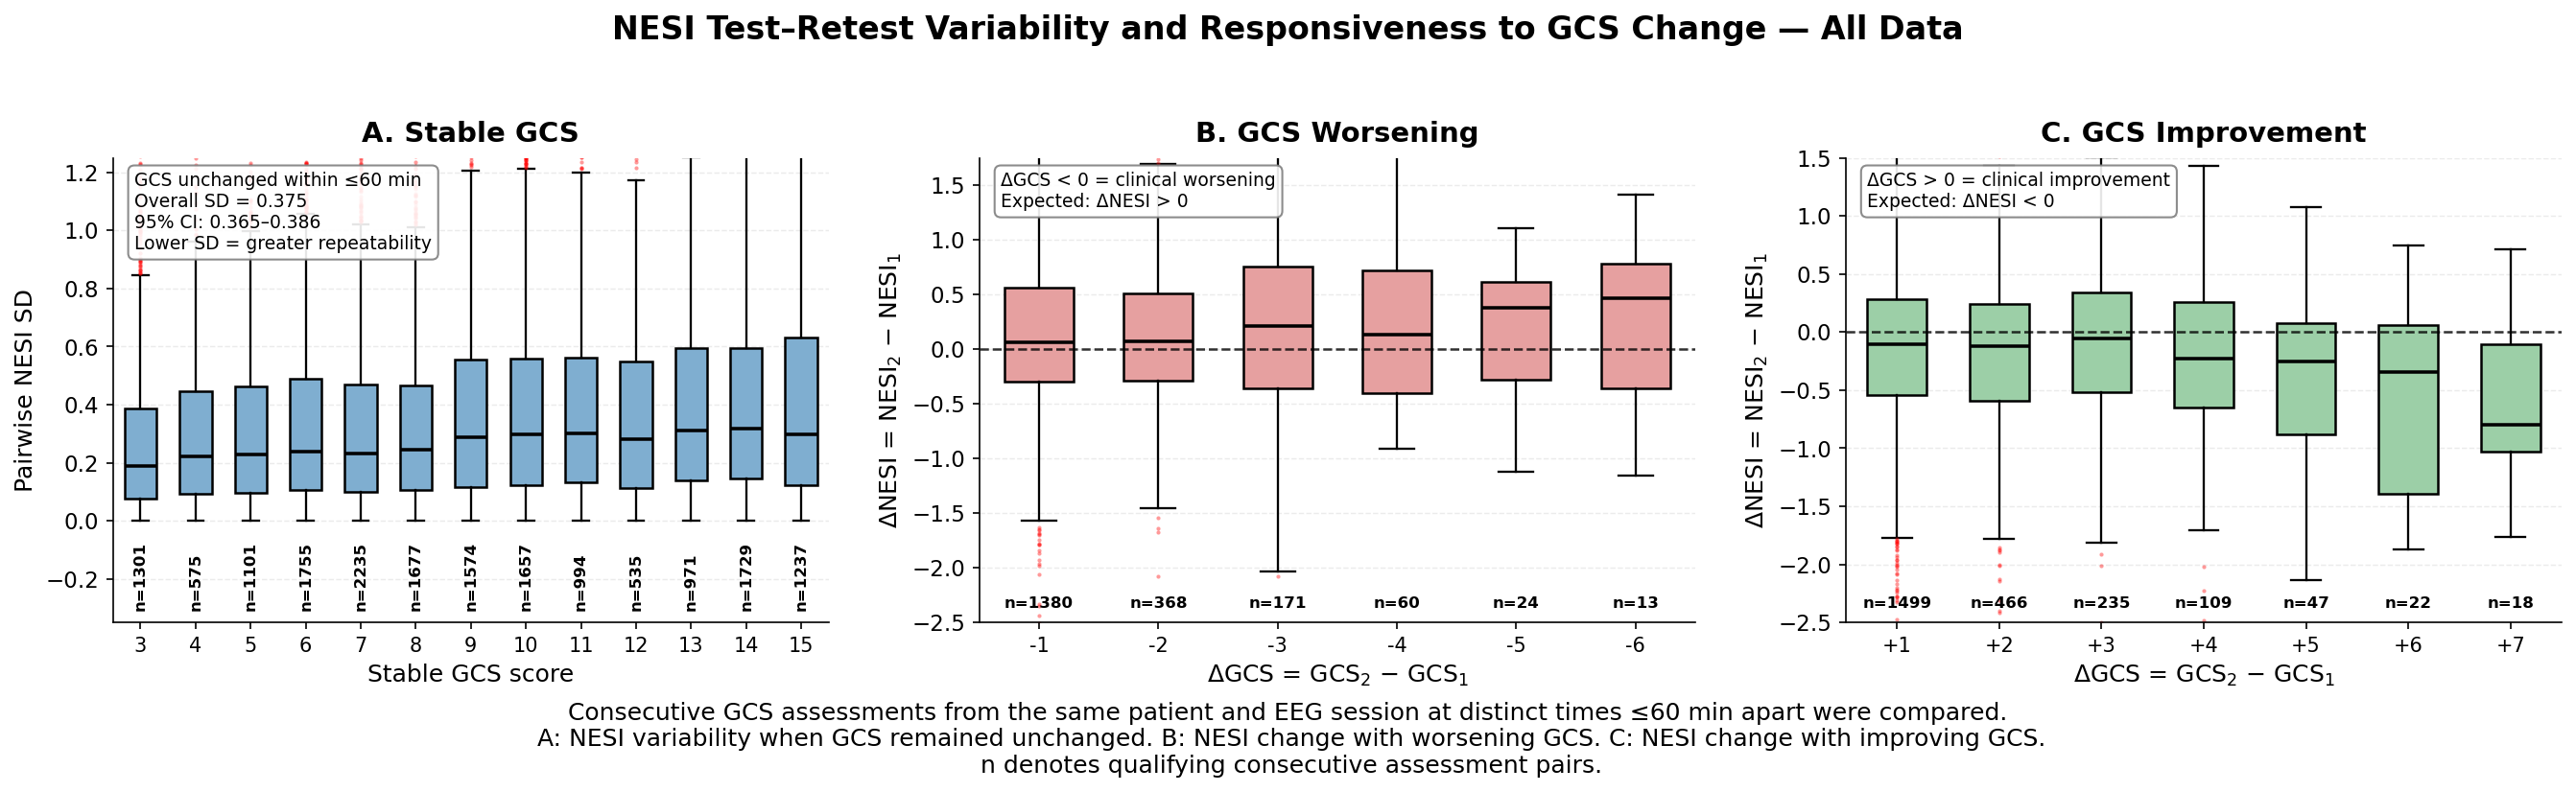

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def plot_nesi_gcs_3panel(df_NESI_GCS,split="all",plot_type="box",save_path=None,max_interval_min=60,n_boot=5000,seed=42,figsize=(18,5.5),dpi=150,save_dpi=500,ylim_A=(-0.05,1.25),ylim_B=(-1.5,1.75),ylim_C=(-2.0,1.5)):
    """
    A: Stable GCS (GCS2=GCS1) -> pairwise NESI SD
    B: GCS worsening (GCS2<GCS1) -> Delta NESI; expected >0
    C: GCS improvement (GCS2>GCS1) -> Delta NESI; expected <0
    Consecutive assessments must be >0 and <=max_interval_min apart within
    the same BDSPPatientID+BidsFolder+SessionID.
    split: "all","train","val","test"
    plot_type: "box","violin"
    """
    df=df_NESI_GCS.copy()
    required=["BDSPPatientID","BidsFolder","SessionID","GCSRecordedDTS","RawScore","NESI"]
    missing=[c for c in required if c not in df.columns]
    if missing: raise ValueError(f"Missing required columns: {missing}")
    split=str(split).lower().strip()
    plot_type=str(plot_type).lower().strip()
    if split not in ["all","train","val","test"]: raise ValueError("split must be 'all','train','val', or 'test'")
    if plot_type not in ["box","violin"]: raise ValueError("plot_type must be 'box' or 'violin'")
    if split!="all":
        if "Split" not in df.columns: raise ValueError("Split column not found")
        df=df[df["Split"].astype(str).str.lower().str.strip()==split].copy()
    if len(df)==0: raise ValueError(f"No rows available for split='{split}'")

    df["BDSPPatientID"]=df["BDSPPatientID"].astype(str).str.strip()
    df["BidsFolder"]=df["BidsFolder"].astype(str).str.strip()
    df["SessionID"]=pd.to_numeric(df["SessionID"],errors="coerce")
    df["GCSRecordedDTS"]=pd.to_datetime(df["GCSRecordedDTS"],errors="coerce")
    df["RawScore"]=pd.to_numeric(df["RawScore"],errors="coerce")
    df["NESI"]=pd.to_numeric(df["NESI"],errors="coerce")
    df=df.dropna(subset=required).copy()
    df=df[df["RawScore"].between(3,15)].copy()
    group_cols=["BDSPPatientID","BidsFolder","SessionID"]
    df=df.sort_values(group_cols+["GCSRecordedDTS"]).reset_index(drop=True)

    # =========================================================================
    # 1. CREATE CONSECUTIVE GCS PAIRS <=1 HOUR APART
    # =========================================================================
    pairs=[]
    for key,g in df.groupby(group_cols,sort=False):
        g=g.sort_values("GCSRecordedDTS").reset_index(drop=True)
        for i in range(len(g)-1):
            a,b=g.iloc[i],g.iloc[i+1]
            dt=(b["GCSRecordedDTS"]-a["GCSRecordedDTS"]).total_seconds()/60
            if not (0<dt<=max_interval_min): continue
            pairs.append({
                "BDSPPatientID":key[0],"BidsFolder":key[1],"SessionID":key[2],
                "Time1":a["GCSRecordedDTS"],"Time2":b["GCSRecordedDTS"],"TimeDiff_min":dt,
                "GCS1":a["RawScore"],"GCS2":b["RawScore"],"NESI1":a["NESI"],"NESI2":b["NESI"],
                "Delta_GCS":b["RawScore"]-a["RawScore"],"Delta_NESI":b["NESI"]-a["NESI"]
            })
    df_pairs=pd.DataFrame(pairs)
    if len(df_pairs)==0: raise RuntimeError(f"No consecutive GCS observations within <= {max_interval_min} min found.")

    # =========================================================================
    # 2. PANEL A — STABLE GCS: NESI SD
    # GCS1=GCS2. Lower NESI SD = greater short-term repeatability.
    # =========================================================================
    df_stable=df_pairs[df_pairs["Delta_GCS"]==0].copy()
    df_stable["Stable_GCS"]=df_stable["GCS1"]
    df_stable["NESI_SD"]=df_stable[["NESI1","NESI2"]].std(axis=1,ddof=1)

    def patient_bootstrap_mean(data,value_col):
        d=data[["BDSPPatientID",value_col]].dropna().copy()
        if len(d)==0: return np.nan,np.nan,np.nan
        observed=d[value_col].mean()
        patients=d["BDSPPatientID"].unique()
        vals={p:d.loc[d["BDSPPatientID"]==p,value_col].values for p in patients}
        rng=np.random.default_rng(seed)
        boot=[]
        for _ in range(n_boot):
            sampled=rng.choice(patients,size=len(patients),replace=True)
            boot.append(np.mean(np.concatenate([vals[p] for p in sampled])))
        lo,hi=np.percentile(boot,[2.5,97.5])
        return observed,lo,hi

    overall_sd,overall_sd_lo,overall_sd_hi=patient_bootstrap_mean(df_stable,"NESI_SD")

    # =========================================================================
    # 3. PANEL B — GCS WORSENING
    # GCS2<GCS1 -> Delta_GCS negative.
    # Example: GCS 12 -> 8 gives Delta_GCS=-4.
    # Expected if NESI tracks worsening: Delta_NESI > 0.
    # =========================================================================
    df_worsening=df_pairs[df_pairs["Delta_GCS"]<0].copy()

    # =========================================================================
    # 4. PANEL C — GCS IMPROVEMENT
    # GCS2>GCS1 -> Delta_GCS positive.
    # Example: GCS 8 -> 12 gives Delta_GCS=+4.
    # Expected if NESI tracks improvement: Delta_NESI < 0.
    # =========================================================================
    df_improvement=df_pairs[df_pairs["Delta_GCS"]>0].copy()

    print("="*78)
    print(f"NESI-GCS ANALYSIS | SPLIT: {split.upper()}")
    print("="*78)
    print(f"Input rows             : {len(df)}")
    print(f"Unique patients        : {df['BDSPPatientID'].nunique()}")
    print(f"All <={max_interval_min}-min pairs      : {len(df_pairs)}")
    print(f"Stable pairs           : {len(df_stable)}")
    print(f"Worsening pairs        : {len(df_worsening)}")
    print(f"Improvement pairs      : {len(df_improvement)}")
    print(f"Overall stable NESI SD : {overall_sd:.3f} (95% CI {overall_sd_lo:.3f}–{overall_sd_hi:.3f})")
    print("\nA. STABLE GCS — NESI SD")
    print(df_stable.groupby("Stable_GCS")["NESI_SD"].agg(["count","mean","median","std"]).round(3))
    print("\nB. GCS WORSENING — DELTA NESI")
    print(df_worsening.groupby("Delta_GCS")["Delta_NESI"].agg(["count","mean","median","std"]).round(3))
    print("\nC. GCS IMPROVEMENT — DELTA NESI")
    print(df_improvement.groupby("Delta_GCS")["Delta_NESI"].agg(["count","mean","median","std"]).round(3))

    # =========================================================================
    # 5. PLOTTER
    # n = number of qualifying consecutive assessment pairs in each category.
    # Boxplot outliers = small red circles.
    # =========================================================================
    def draw(ax,data,x_col,y_col,categories,color,title,xlabel,ylabel,ylim=None,zero=False,plus=False):
        values=[data.loc[data[x_col]==c,y_col].dropna().values for c in categories]
        counts=[len(v) for v in values]
        pos=np.arange(len(categories))
        if plot_type=="box":
            vals=[v if len(v)>0 else np.array([np.nan]) for v in values]
            ax.boxplot(vals,positions=pos,widths=.58,patch_artist=True,showfliers=True,whis=1.5,
                       boxprops=dict(facecolor=color,edgecolor="black",linewidth=1.2),
                       medianprops=dict(color="black",linewidth=1.7),
                       whiskerprops=dict(color="black",linewidth=1.1),
                       capprops=dict(color="black",linewidth=1.1),
                       flierprops=dict(marker="o",markersize=2,markerfacecolor="red",markeredgecolor="red",markeredgewidth=0,alpha=.4))
        else:
            for p,v in zip(pos,values):
                if len(v)==0: continue
                vp=ax.violinplot([v],positions=[p],widths=.72,showmeans=False,showmedians=False,showextrema=False)
                for body in vp["bodies"]:
                    body.set_facecolor(color); body.set_edgecolor("black"); body.set_linewidth(1); body.set_alpha(.75)
                q1,med,q3=np.percentile(v,[25,50,75])
                ax.vlines(p,q1,q3,color="black",linewidth=5,zorder=3)
                ax.hlines(med,p-.12,p+.12,color="white",linewidth=2.2,zorder=4)
        if zero: ax.axhline(0,color="black",linestyle="--",linewidth=1.2,alpha=.8)
        labels=[f"+{int(c)}" if plus and c>0 else str(int(c)) for c in categories]
        ax.set_xticks(pos); ax.set_xticklabels(labels,fontsize=10,rotation=0)
        ax.set_xlabel(xlabel,fontsize=12); ax.set_ylabel(ylabel,fontsize=12)
        ax.set_title(title,fontsize=14,fontweight="bold",pad=8)
        ax.tick_params(axis="y",labelsize=11)
        ax.yaxis.grid(True,linestyle="--",linewidth=.7,alpha=.25)
        ax.set_axisbelow(True); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        if ylim is not None: ax.set_ylim(ylim)
        ymin,ymax=ax.get_ylim(); yr=ymax-ymin
        for p,n in zip(pos,counts):
            ax.text(p,ymin+.025*yr,f"n={n}",ha="center",va="bottom",fontsize=8,fontweight="bold",rotation=90 if len(categories)>8 else 0)

    # =========================================================================
    # 6. THREE-PANEL FIGURE
    #
    # Stable x-axis = actual GCS 3...15.
    # Worsening x-axis = -1...-12.
    # Improvement x-axis = +1...+12.
    # =========================================================================
    stable_order=list(range(3,16))
    worsening_order=list(range(-1,-7,-1))
    improvement_order=list(range(1,8))

    fig,axes=plt.subplots(1,3,figsize=figsize,dpi=dpi)

    draw(axes[0],df_stable,"Stable_GCS","NESI_SD",stable_order,"#7FAED0",
         "A. Stable GCS","Stable GCS score","Pairwise NESI SD",ylim=ylim_A)
    axes[0].text(.03,.97,
                 f"GCS unchanged within ≤{max_interval_min} min\nOverall SD = {overall_sd:.3f}\n95% CI: {overall_sd_lo:.3f}–{overall_sd_hi:.3f}\nLower SD = greater repeatability",
                 transform=axes[0].transAxes,ha="left",va="top",fontsize=9,
                 bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.9))

    draw(axes[1],df_worsening,"Delta_GCS","Delta_NESI",worsening_order,"#E6A0A0",
         "B. GCS Worsening",r"$\Delta$GCS = GCS$_2$ − GCS$_1$",r"$\Delta$NESI = NESI$_2$ − NESI$_1$",
         ylim=ylim_B,zero=True)
    axes[1].text(.03,.97,"ΔGCS < 0 = clinical worsening\nExpected: ΔNESI > 0",
                 transform=axes[1].transAxes,ha="left",va="top",fontsize=9,
                 bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.9))

    draw(axes[2],df_improvement,"Delta_GCS","Delta_NESI",improvement_order,"#9CCFA7",
         "C. GCS Improvement",r"$\Delta$GCS = GCS$_2$ − GCS$_1$",r"$\Delta$NESI = NESI$_2$ − NESI$_1$",
         ylim=ylim_C,zero=True,plus=True)
    axes[2].text(.03,.97,"ΔGCS > 0 = clinical improvement\nExpected: ΔNESI < 0",
                 transform=axes[2].transAxes,ha="left",va="top",fontsize=9,
                 bbox=dict(boxstyle="round,pad=.35",facecolor="white",edgecolor="gray",alpha=.9))

    split_title="All Data" if split=="all" else f"{split.capitalize()} Split"
    fig.suptitle(f"NESI Test–Retest Variability and Responsiveness to GCS Change — {split_title}",
                 fontsize=16,fontweight="bold",y=.98)
    fig.text(.5,.015,
             f"Consecutive GCS assessments from the same patient and EEG session at distinct times ≤{max_interval_min} min apart were compared.\n "
             "A: NESI variability when GCS remained unchanged. B: NESI change with worsening GCS. C: NESI change with improving GCS.\n "
             "n denotes qualifying consecutive assessment pairs.",
             ha="center",va="bottom",fontsize=12)
    plt.tight_layout(rect=[0,.10,1,.94],w_pad=2.5)

    if save_path is not None:
        plt.savefig(save_path,dpi=save_dpi,bbox_inches="tight")
        print(f"\nFigure saved to: {save_path}")
    plt.show()

    return {
        "df_pairs":df_pairs,
        "df_stable":df_stable,
        "df_worsening":df_worsening,
        "df_improvement":df_improvement,
        "overall_sd":overall_sd,
        "overall_sd_ci":(overall_sd_lo,overall_sd_hi)
    }

# CALL
results_GCS=plot_nesi_gcs_3panel(
    df_NESI_GCS=df_NESI_GCS,
    split="all",             # "all","train","val","test"
    plot_type="box",         # "box","violin"
    save_path=None,          # None = no save
    max_interval_min=60,
    ylim_A=(-0.35,1.25),
    ylim_B=(-2.5,1.75),
    ylim_C=(-2.5,1.5)
)